#  — Correlation Analysis & Annotator Grouping
### Modeling Disagreement in LLM Harm Annotation

---

## Goals This Week

1. **Correlation Analysis** — find highly correlated features within each category
2. **Remove correlated features** — keep only non-redundant features (threshold r > 0.9)
3. **Re-test models** — does removing correlated features improve performance?
4. **Annotator grouping** — for highly contested prompts, who rates them harmful vs harmless?
5. **Write findings** — what does each test tell us?

## Why Correlation Analysis?

If two features are highly correlated, they carry the same information.
The model cannot tell which one is actually driving the prediction.
This causes **multicollinearity** — coefficients become unstable and unreliable.

**Solution:** Keep only one feature from each highly correlated pair.

**Threshold:** r > 0.9 (only remove very highly correlated features)


## 0. Setup

In [1]:
import sys, os, warnings
warnings.filterwarnings('ignore')

REPO_ROOT = r"C:\Users\hp\PluriHarms-release"
sys.path.insert(0, os.path.join(REPO_ROOT, 'src'))
os.chdir(REPO_ROOT)
os.makedirs("outputs", exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import KFold
from data_loader import load_data, get_rating_columns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

# Same KF as before — reproducible
KF = KFold(n_splits=5, shuffle=True, random_state=42)

CORR_THRESHOLD = 0.9  # remove features with correlation > this

print("Setup complete.")
print(f"Correlation threshold: r > {CORR_THRESHOLD}")

Setup complete.
Correlation threshold: r > 0.9


## 1. Load Data

In [2]:
annotations, prompts = load_data()
rating_cols = get_rating_columns(annotations)

# Feature categories
action_cols = [c for c in prompts.columns if c.startswith('action_')]
effect_cols = [c for c in prompts.columns if c.startswith('effect_')]
cat_A = action_cols + effect_cols
cat_B = [c for c in prompts.columns if c.startswith('value_topic_')]

tfidf = TfidfVectorizer(max_features=100, stop_words='english', ngram_range=(1,2))
tfidf_matrix = tfidf.fit_transform(prompts['Question_Content'])
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=[f'tfidf_{w}' for w in tfidf.get_feature_names_out()],
    index=prompts['Question_Index']
).reset_index()
cat_C = [c for c in tfidf_df.columns if c.startswith('tfidf_')]

cat_D_raw = ['Gender', 'Age', 'Political_Affiliation', 'Education',
             'Social_Media_Frequency', 'Toxicity_Experience',
             'Income', 'Religion_Importance',
             'Race_Ethnicity', 'Sexual_Orientation']
cat_E = ['Factor_1', 'Factor_2', 'Factor_3']

print(f"Data loaded: {annotations.shape[0]} annotators, {prompts.shape[0]} prompts")
print(f"A: {len(cat_A)} | B: {len(cat_B)} | C: {len(cat_C)} | D: {len(cat_D_raw)} | E: {len(cat_E)}")

Data loaded: 100 annotators, 150 prompts
A: 23 | B: 39 | C: 100 | D: 10 | E: 3


## 2. Prepare Data

In [3]:
# Average ratings per prompt
avg_ratings = {}
for col in rating_cols:
    q_idx = int(col.replace('Rating_', ''))
    avg_ratings[q_idx] = annotations[col].mean()

# Rating matrix for disagreement analysis
ratings_matrix = annotations[rating_cols].copy()
ratings_matrix.columns = [int(c.replace('Rating_', '')) for c in rating_cols]

# Disagreement metrics per prompt
disagree_df = pd.DataFrame({
    'question_index': list(avg_ratings.keys()),
    'avg_rating'    : list(avg_ratings.values()),
    'std_rating'    : [ratings_matrix[q].std() for q in avg_ratings.keys()],
})
disagree_df['highly_contested'] = disagree_df['std_rating'] > disagree_df['std_rating'].median()

print(f"Total prompts: {len(disagree_df)}")
print(f"Highly contested (std > median): {disagree_df['highly_contested'].sum()}")
print(f"Median std: {disagree_df['std_rating'].median():.2f}")

# Long format
rows = []
for _, ann_row in annotations.iterrows():
    for col in rating_cols:
        q_idx  = int(col.replace('Rating_', ''))
        rating = ann_row[col]
        if pd.isna(rating):
            continue
        prompt_row = prompts[prompts['Question_Index'] == q_idx]
        if len(prompt_row) == 0:
            continue
        row = {
            'rating'         : rating,
            'question_index' : q_idx,
            'Participant_ID' : ann_row['Participant_ID'],
        }
        for c in cat_A + cat_B:
            row[c] = prompt_row[c].values[0]
        for c in cat_D_raw + cat_E:
            row[c] = ann_row[c]
        tfidf_row = tfidf_df[tfidf_df['Question_Index'] == q_idx]
        if len(tfidf_row) > 0:
            for c in cat_C:
                row[c] = tfidf_row[c].values[0]
        rows.append(row)

long_df = pd.DataFrame(rows)
long_df_encoded = pd.get_dummies(long_df, columns=cat_D_raw, drop_first=True)
long_df_encoded = long_df_encoded.fillna(long_df_encoded.median(numeric_only=True))
cat_D_encoded = [c for c in long_df_encoded.columns
                 if any(c.startswith(d + '_') for d in cat_D_raw)]

# Fixed prompt split
np.random.seed(42)
all_prompts = prompts['Question_Index'].values.copy()
np.random.shuffle(all_prompts)
train_prompts = all_prompts[:100]
test_prompts  = all_prompts[100:]

long_train = long_df_encoded[long_df_encoded['question_index'].isin(train_prompts)]
long_test  = long_df_encoded[long_df_encoded['question_index'].isin(test_prompts)]

print(f"Long format: {long_df_encoded.shape[0]:,} rows")

Total prompts: 150
Highly contested (std > median): 75
Median std: 29.61
Long format: 14,725 rows


## 3. Evaluation Functions

In [4]:
def cv_evaluate(X, y):
    r2s, maes = [], []
    for tr, val in KF.split(X):
        m = Ridge(alpha=1.0)
        m.fit(X.iloc[tr], y.iloc[tr])
        p = m.predict(X.iloc[val])
        r2s.append(r2_score(y.iloc[val], p))
        maes.append(mean_absolute_error(y.iloc[val], p))
    return round(np.mean(r2s), 3), round(np.std(r2s), 3), round(np.mean(maes), 2)

def test_evaluate(X_tr, y_tr, X_te, y_te):
    m = Ridge(alpha=1.0)
    m.fit(X_tr, y_tr)
    p = m.predict(X_te)
    return round(r2_score(y_te, p), 3), round(mean_absolute_error(y_te, p), 2), p, m

print("Evaluation functions ready.")

Evaluation functions ready.


## 4. Correlation Analysis

For each feature category, we compute the correlation matrix and identify
pairs of features with correlation > 0.9.

**Why r > 0.9?**
Features correlated above 0.9 carry nearly identical information.
Keeping both does not add value — it only introduces multicollinearity.

**Method:**
For each highly correlated pair, we keep the feature with higher variance
(more informative) and remove the other.


In [5]:
def remove_correlated(df, features, threshold=CORR_THRESHOLD):
    """
    Remove highly correlated features.
    For each correlated pair (r > threshold), keep the one with higher variance.
    Returns: list of features to keep, list of features removed.
    """
    data = df[features].dropna()
    corr_matrix = data.corr().abs()

    # Upper triangle only (avoid double-counting)
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    # Find pairs above threshold
    to_remove = set()
    pairs = []
    for col in upper.columns:
        correlated_with = upper[col][upper[col] > threshold].index.tolist()
        for other in correlated_with:
            # Keep the one with higher variance
            var_col   = data[col].var()
            var_other = data[other].var()
            remove = other if var_col >= var_other else col
            keep   = col   if var_col >= var_other else other
            to_remove.add(remove)
            pairs.append({'keep': keep, 'remove': remove,
                          'correlation': round(upper.loc[other, col]
                                               if other in upper.index else
                                               upper.loc[col, other], 3)})

    kept = [f for f in features if f not in to_remove]
    return kept, list(to_remove), pairs

print("remove_correlated() function ready.")

remove_correlated() function ready.


In [6]:
# ── Category A: SafetyAnalyst ────────────────────────────────
print("=" * 55)
print("CATEGORY A — SafetyAnalyst (action_* + effect_*)")
print("=" * 55)

cat_A_kept, cat_A_removed, cat_A_pairs = remove_correlated(
    prompts, cat_A, CORR_THRESHOLD
)

print(f"Original features : {len(cat_A)}")
print(f"Removed           : {len(cat_A_removed)}")
print(f"Kept              : {len(cat_A_kept)}")
if cat_A_pairs:
    print(f"\nCorrelated pairs (r > {CORR_THRESHOLD}):")
    for p in cat_A_pairs:
        print(f"  KEEP: {p['keep']:<35} REMOVE: {p['remove']:<35} r={p['correlation']}")
else:
    print(f"\nNo pairs with r > {CORR_THRESHOLD} found.")

CATEGORY A — SafetyAnalyst (action_* + effect_*)
Original features : 23
Removed           : 0
Kept              : 23

No pairs with r > 0.9 found.


In [7]:
# ── Category B: Kaleido ──────────────────────────────────────
print("=" * 55)
print("CATEGORY B — Kaleido (value_topic_*)")
print("=" * 55)

cat_B_kept, cat_B_removed, cat_B_pairs = remove_correlated(
    prompts, cat_B, CORR_THRESHOLD
)

print(f"Original features : {len(cat_B)}")
print(f"Removed           : {len(cat_B_removed)}")
print(f"Kept              : {len(cat_B_kept)}")
if cat_B_pairs:
    print(f"\nCorrelated pairs (r > {CORR_THRESHOLD}):")
    for p in cat_B_pairs:
        print(f"  KEEP: {p['keep']:<35} REMOVE: {p['remove']:<35} r={p['correlation']}")
else:
    print(f"\nNo pairs with r > {CORR_THRESHOLD} found.")

CATEGORY B — Kaleido (value_topic_*)
Original features : 39
Removed           : 0
Kept              : 39

No pairs with r > 0.9 found.


In [8]:
# ── Category D: Demographic ──────────────────────────────────
print("=" * 55)
print("CATEGORY D — Demographic (encoded)")
print("=" * 55)

cat_D_kept, cat_D_removed, cat_D_pairs = remove_correlated(
    long_df_encoded, cat_D_encoded, CORR_THRESHOLD
)

print(f"Original features : {len(cat_D_encoded)}")
print(f"Removed           : {len(cat_D_removed)}")
print(f"Kept              : {len(cat_D_kept)}")
if cat_D_pairs:
    print(f"\nCorrelated pairs (r > {CORR_THRESHOLD}):")
    for p in cat_D_pairs:
        print(f"  KEEP: {p['keep']:<45} REMOVE: {p['remove']:<45} r={p['correlation']}")
else:
    print(f"\nNo pairs with r > {CORR_THRESHOLD} found.")

CATEGORY D — Demographic (encoded)
Original features : 46
Removed           : 0
Kept              : 46

No pairs with r > 0.9 found.


In [9]:
# ── Category E: Psychological ────────────────────────────────
print("=" * 55)
print("CATEGORY E — Psychological (Factor_1/2/3)")
print("=" * 55)

cat_E_kept, cat_E_removed, cat_E_pairs = remove_correlated(
    long_df_encoded, cat_E, CORR_THRESHOLD
)

print(f"Original features : {len(cat_E)}")
print(f"Removed           : {len(cat_E_removed)}")
print(f"Kept              : {len(cat_E_kept)}")
if cat_E_pairs:
    print(f"\nCorrelated pairs (r > {CORR_THRESHOLD}):")
    for p in cat_E_pairs:
        print(f"  KEEP: {p['keep']:<25} REMOVE: {p['remove']:<25} r={p['correlation']}")
else:
    print(f"\nNo pairs with r > {CORR_THRESHOLD} found.")

CATEGORY E — Psychological (Factor_1/2/3)
Original features : 3
Removed           : 0
Kept              : 3

No pairs with r > 0.9 found.


## 5. Correlation Heatmaps

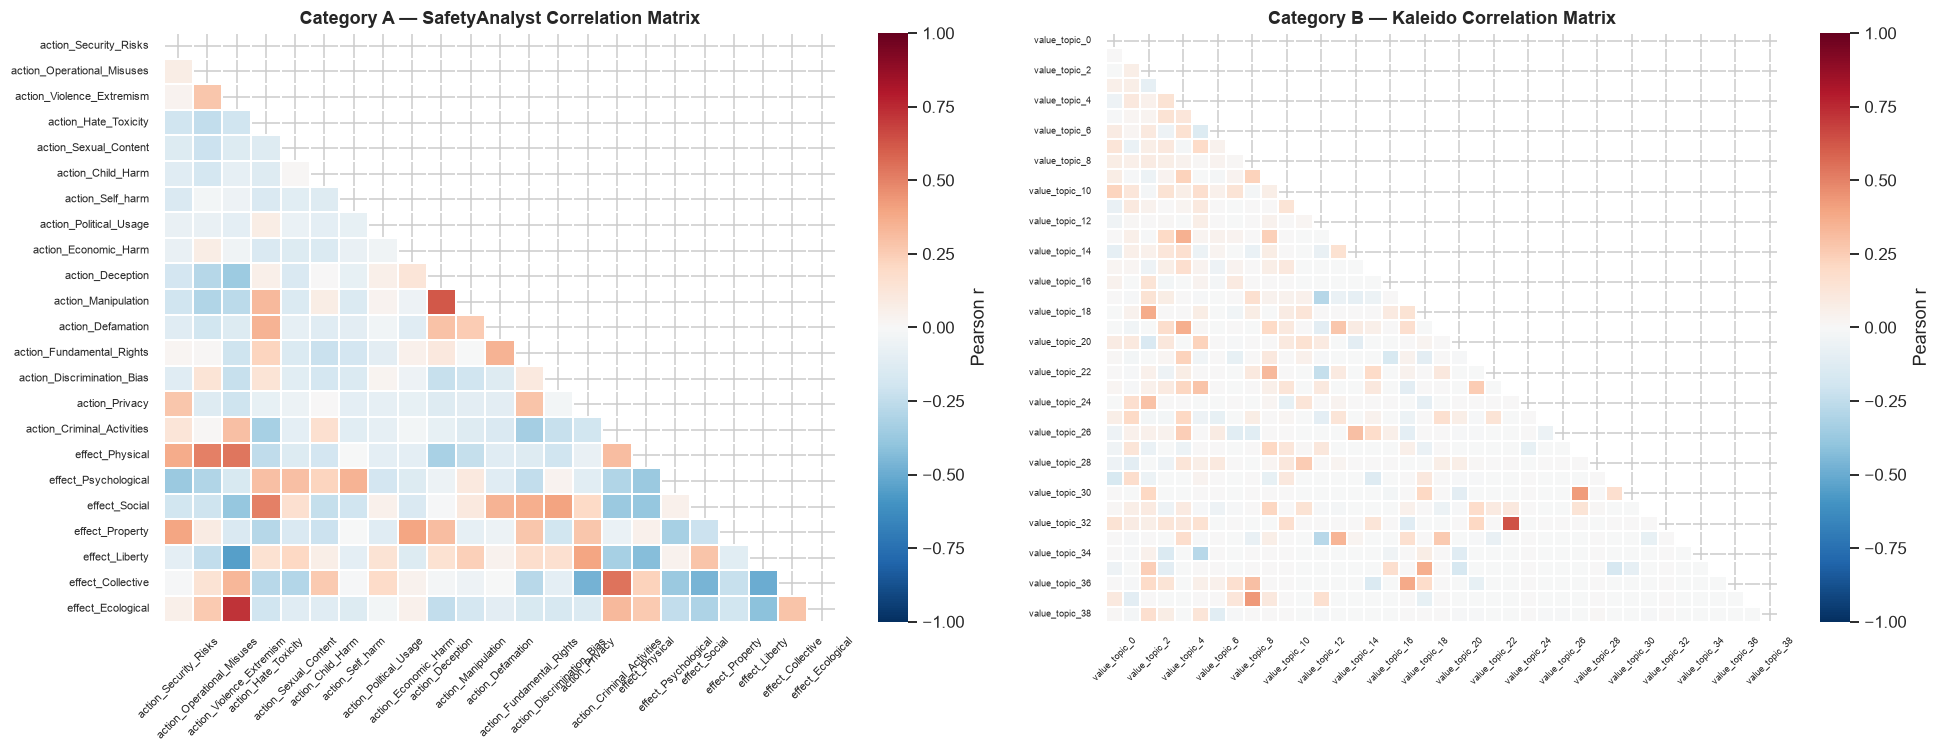

Saved: outputs/fig_correlation_heatmaps.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Category A heatmap
corr_A = prompts[cat_A].corr()
mask_A = np.triu(np.ones_like(corr_A, dtype=bool))
sns.heatmap(corr_A, mask=mask_A, ax=axes[0],
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=False, linewidths=0.3,
            cbar_kws={'label': 'Pearson r'})
axes[0].set_title('Category A — SafetyAnalyst Correlation Matrix',
                   fontweight='bold')
axes[0].tick_params(axis='x', rotation=45, labelsize=7)
axes[0].tick_params(axis='y', labelsize=7)

# Category B heatmap
corr_B = prompts[cat_B].corr()
mask_B = np.triu(np.ones_like(corr_B, dtype=bool))
sns.heatmap(corr_B, mask=mask_B, ax=axes[1],
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=False, linewidths=0.3,
            cbar_kws={'label': 'Pearson r'})
axes[1].set_title('Category B — Kaleido Correlation Matrix',
                   fontweight='bold')
axes[1].tick_params(axis='x', rotation=45, labelsize=6)
axes[1].tick_params(axis='y', labelsize=6)

plt.tight_layout()
plt.savefig("outputs/fig_correlation_heatmaps.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_correlation_heatmaps.png")

## 6. Re-test Models with Cleaned Features

Now we test whether removing correlated features improves model performance.

**Base comparison:**
- Original features (with correlated)
- Cleaned features (correlated removed)


In [11]:
print("=" * 60)
print("MODEL COMPARISON — Original vs Cleaned Features")
print("=" * 60)
print()

results_comparison = []

# ── Test sets ────────────────────────────────────────────────
y_tr = long_train['rating']
y_te = long_test['rating']

feature_sets = {
    'A original'  : [c for c in cat_A      if c in long_train.columns],
    'A cleaned'   : [c for c in cat_A_kept  if c in long_train.columns],
    'B original'  : [c for c in cat_B      if c in long_train.columns],
    'B cleaned'   : [c for c in cat_B_kept  if c in long_train.columns],
    'A+D+E original': list(dict.fromkeys(
        [c for c in cat_A + cat_D_encoded + cat_E if c in long_train.columns])),
    'A+D+E cleaned' : list(dict.fromkeys(
        [c for c in cat_A_kept + cat_D_kept + cat_E_kept if c in long_train.columns])),
}

for name, feats in feature_sets.items():
    if not feats:
        print(f"{name}: no features available")
        continue
    cv_r2, cv_std, cv_mae = cv_evaluate(long_train[feats], y_tr)
    te_r2, te_mae, _, _   = test_evaluate(long_train[feats], y_tr,
                                           long_test[feats],  y_te)
    results_comparison.append({
        'Feature set' : name,
        'N features'  : len(feats),
        'CV R²'       : cv_r2,
        'CV std'      : cv_std,
        'Test R²'     : te_r2,
        'Test MAE'    : te_mae,
    })
    print(f"{name:<25} N={len(feats):>3}  CV R²={cv_r2:.3f}±{cv_std:.3f}  Test R²={te_r2:.3f}  MAE={te_mae:.2f}")

comp_df = pd.DataFrame(results_comparison)

MODEL COMPARISON — Original vs Cleaned Features

A original                N= 23  CV R²=0.242±0.020  Test R²=0.021  MAE=30.39
A cleaned                 N= 23  CV R²=0.242±0.020  Test R²=0.021  MAE=30.39
B original                N= 39  CV R²=0.182±0.013  Test R²=-0.329  MAE=36.26
B cleaned                 N= 39  CV R²=0.182±0.013  Test R²=-0.329  MAE=36.26
A+D+E original            N= 72  CV R²=0.297±0.026  Test R²=0.090  MAE=28.80
A+D+E cleaned             N= 72  CV R²=0.297±0.026  Test R²=0.090  MAE=28.80


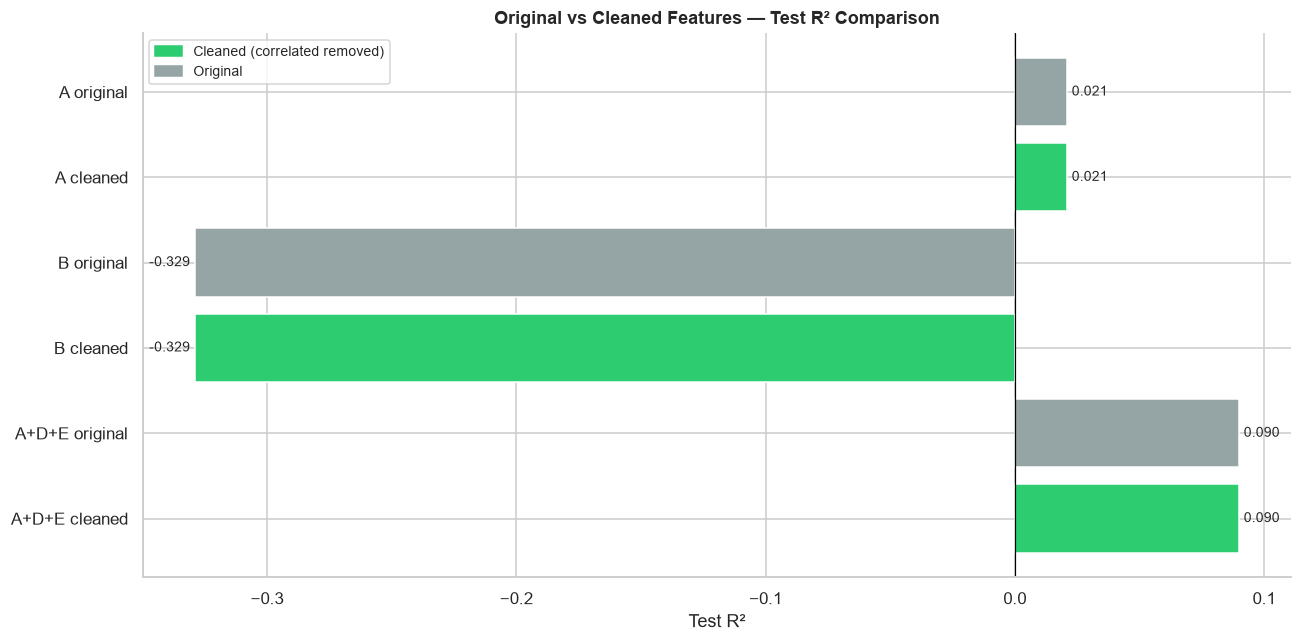

Saved: outputs/fig_cleaned_comparison.png


In [12]:
# Visualization
fig, ax = plt.subplots(figsize=(12, 6))

colors = []
for name in comp_df['Feature set']:
    if 'cleaned' in name:
        colors.append('#2ecc71')
    else:
        colors.append('#95a5a6')

bars = ax.barh(comp_df['Feature set'][::-1], comp_df['Test R²'][::-1],
               color=colors[::-1], edgecolor='white')
ax.bar_label(bars, labels=[f"{v:.3f}" for v in comp_df['Test R²'][::-1]],
             padding=3, fontsize=9)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Test R²')
ax.set_title('Original vs Cleaned Features — Test R² Comparison',
             fontweight='bold', fontsize=12)

from matplotlib.patches import Patch
legend = [Patch(color='#2ecc71', label='Cleaned (correlated removed)'),
          Patch(color='#95a5a6', label='Original')]
ax.legend(handles=legend, fontsize=9)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig("outputs/fig_cleaned_comparison.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_cleaned_comparison.png")

## 7. Annotator Grouping — Highly Contested Prompts

For highly contested prompts (std > median), we split annotators into two groups:
- **Group LOW:** annotators who rated the prompt 0–50 (harmless)
- **Group HIGH:** annotators who rated the prompt 51–100 (harmful)

**Question:** Who are these two groups? Are they systematically different
in their demographics or psychological factors?

This helps us understand: **what predicts which camp an annotator falls into?**


In [13]:
# Highly contested prompts
contested_prompts = disagree_df[disagree_df['highly_contested']]['question_index'].tolist()
print(f"Highly contested prompts: {len(contested_prompts)}")
print(f"Std threshold (median): {disagree_df['std_rating'].median():.2f}")
print()

# For each contested prompt, split annotators into LOW and HIGH groups
group_results = []

for q_idx in contested_prompts:
    col = f'Rating_{q_idx}'
    if col not in annotations.columns:
        continue

    ratings = annotations[['Participant_ID'] + cat_D_raw + cat_E + [col]].copy()
    ratings = ratings.dropna(subset=[col])
    ratings['group'] = ratings[col].apply(lambda x: 'HIGH' if x > 50 else 'LOW')

    low  = ratings[ratings['group'] == 'LOW']
    high = ratings[ratings['group'] == 'HIGH']

    if len(low) < 5 or len(high) < 5:
        continue

    group_results.append({
        'question_index' : q_idx,
        'n_low'          : len(low),
        'n_high'         : len(high),
        'mean_rating_low': low[col].mean(),
        'mean_rating_high': high[col].mean(),
        'std_rating'     : disagree_df[disagree_df['question_index']==q_idx]['std_rating'].values[0],
        'Factor1_low'    : low['Factor_1'].mean(),
        'Factor1_high'   : high['Factor_1'].mean(),
        'Factor2_low'    : low['Factor_2'].mean(),
        'Factor2_high'   : high['Factor_2'].mean(),
        'Factor3_low'    : low['Factor_3'].mean(),
        'Factor3_high'   : high['Factor_3'].mean(),
    })

group_df = pd.DataFrame(group_results).sort_values('std_rating', ascending=False)

print(f"Prompts with enough annotators in both groups: {len(group_df)}")
print()
print("Top 10 most contested prompts — Group comparison:")
print(group_df[['question_index', 'n_low', 'n_high',
                 'Factor1_low', 'Factor1_high',
                 'Factor2_low', 'Factor2_high']].head(10).round(2).to_string(index=False))

Highly contested prompts: 75
Std threshold (median): 29.61

Prompts with enough annotators in both groups: 75

Top 10 most contested prompts — Group comparison:
 question_index  n_low  n_high  Factor1_low  Factor1_high  Factor2_low  Factor2_high
             93     51      40         0.52         -0.13        -0.81          0.75
             50     27      70         0.69         -0.19         1.11         -0.36
             20     60      40        -0.48          0.72        -0.23          0.35
             94     42      48         0.84          0.04        -0.55          0.50
            108     52      43         0.14          0.28        -0.24          0.15
            123     40      60         1.39         -0.93        -0.33          0.22
            138     32      67         0.72         -0.29        -0.46          0.27
             67     45      51         0.56         -0.07        -0.23          0.12
             23     32      59         1.28         -0.25        -0.58    

In [14]:
# Factor differences between LOW and HIGH groups
group_df['Factor1_diff'] = group_df['Factor1_high'] - group_df['Factor1_low']
group_df['Factor2_diff'] = group_df['Factor2_high'] - group_df['Factor2_low']
group_df['Factor3_diff'] = group_df['Factor3_high'] - group_df['Factor3_low']

print("Average factor differences (HIGH group - LOW group):")
print(f"  Factor_1 diff: {group_df['Factor1_diff'].mean():+.3f}")
print(f"  Factor_2 diff: {group_df['Factor2_diff'].mean():+.3f}")
print(f"  Factor_3 diff: {group_df['Factor3_diff'].mean():+.3f}")
print()
print("Interpretation:")
if group_df['Factor1_diff'].mean() > 0:
    print("  Factor_1: HIGH group (harmful) has HIGHER authority/power values")
else:
    print("  Factor_1: HIGH group (harmful) has LOWER authority/power values")
if group_df['Factor2_diff'].mean() > 0:
    print("  Factor_2: HIGH group (harmful) has HIGHER empathy")
else:
    print("  Factor_2: HIGH group (harmful) has LOWER empathy")
if group_df['Factor3_diff'].mean() > 0:
    print("  Factor_3: HIGH group (harmful) has HIGHER tradition values")
else:
    print("  Factor_3: HIGH group (harmful) has LOWER tradition values")

Average factor differences (HIGH group - LOW group):
  Factor_1 diff: -0.598
  Factor_2 diff: +0.476
  Factor_3 diff: -0.065

Interpretation:
  Factor_1: HIGH group (harmful) has LOWER authority/power values
  Factor_2: HIGH group (harmful) has HIGHER empathy
  Factor_3: HIGH group (harmful) has LOWER tradition values


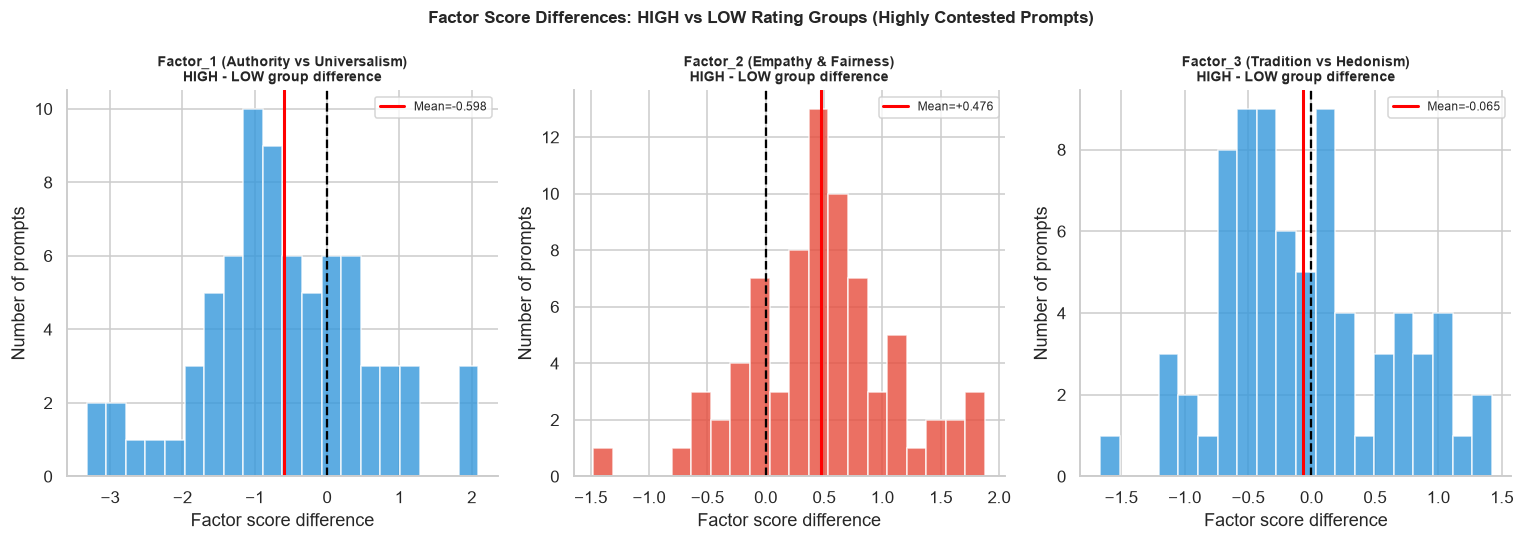

Saved: outputs/fig_group_factor_diff.png


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

factors = ['Factor1_diff', 'Factor2_diff', 'Factor3_diff']
titles  = ['Factor_1 (Authority vs Universalism)',
           'Factor_2 (Empathy & Fairness)',
           'Factor_3 (Tradition vs Hedonism)']
colors  = ['#e74c3c' if group_df[f].mean() > 0 else '#3498db' for f in factors]

for ax, factor, title, color in zip(axes, factors, titles, colors):
    ax.hist(group_df[factor], bins=20, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(0, color='black', linewidth=1.5, linestyle='--')
    ax.axvline(group_df[factor].mean(), color='red', linewidth=2,
               label=f'Mean={group_df[factor].mean():+.3f}')
    ax.set_title(f'{title}\nHIGH - LOW group difference', fontweight='bold', fontsize=9)
    ax.set_xlabel('Factor score difference')
    ax.set_ylabel('Number of prompts')
    ax.legend(fontsize=8)
    ax.spines[['top','right']].set_visible(False)

fig.suptitle('Factor Score Differences: HIGH vs LOW Rating Groups (Highly Contested Prompts)',
             fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig("outputs/fig_group_factor_diff.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_group_factor_diff.png")

## 8. Frequency Counting — 0-50 vs 50-100

For all highly contested prompts, count how many annotators fall in each camp.
This gives us a picture of how polarized the ratings are.


Top 15 most contested prompts — 0-50 vs 51-100 split:
 question_index  n_low (0-50)  n_high (51-100)  pct_low  pct_high  std_rating
             93            51               40     56.0      44.0   36.564553
             50            27               70     27.8      72.2   35.919371
             20            60               40     60.0      40.0   35.606257
             94            42               48     46.7      53.3   35.505349
            108            52               43     54.7      45.3   35.131294
            123            40               60     40.0      60.0   34.883174
            138            32               67     32.3      67.7   34.634080
             67            45               51     46.9      53.1   34.610488
             23            32               59     35.2      64.8   34.583946
            106            48               51     48.5      51.5   34.454593
             75            28               69     28.9      71.1   34.454543
          

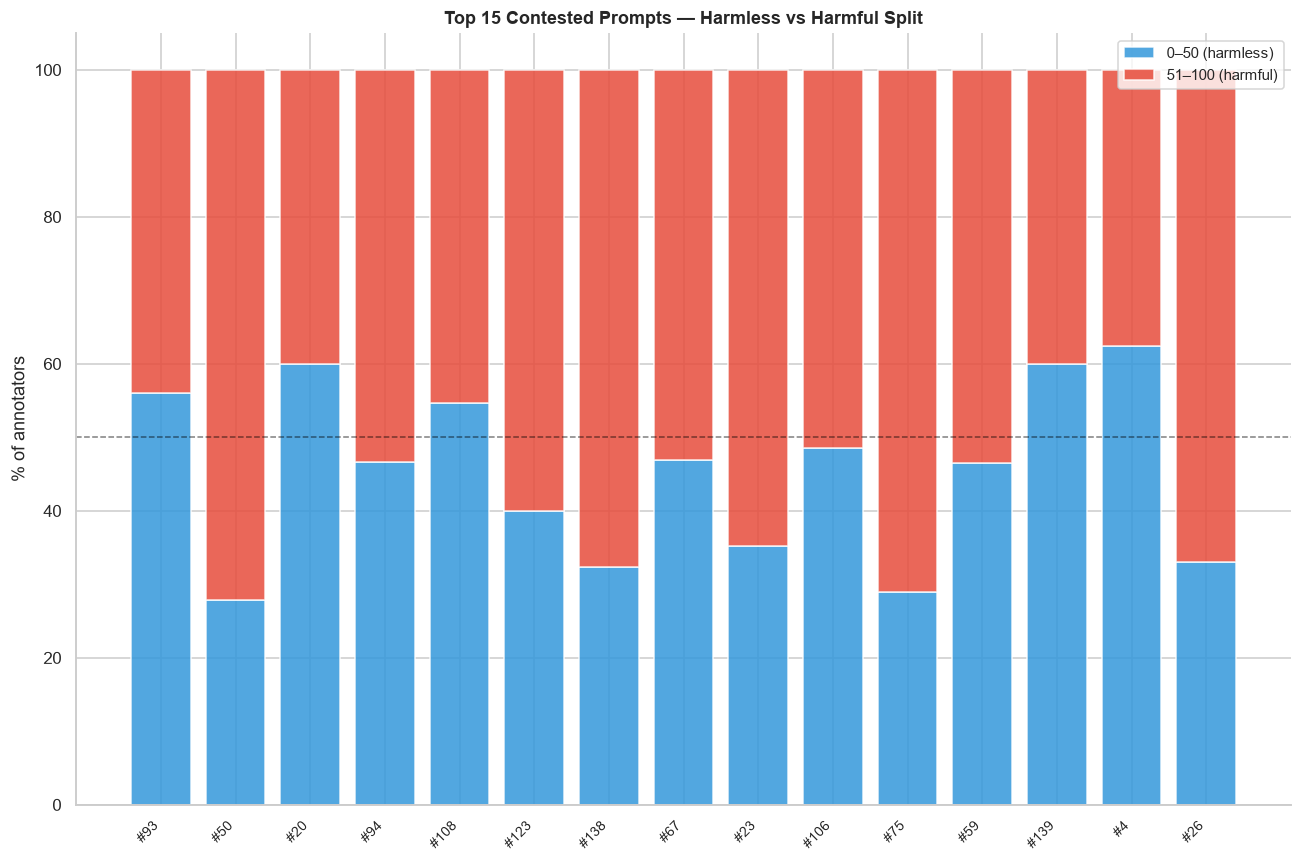

Saved: outputs/fig_frequency_split.png


In [18]:
freq_results = []

for q_idx in contested_prompts:
    col = f'Rating_{q_idx}'
    if col not in annotations.columns:
        continue
    ratings = annotations[col].dropna()
    n_low  = (ratings <= 50).sum()
    n_high = (ratings > 50).sum()
    freq_results.append({
        'question_index': q_idx,
        'n_low (0-50)'  : n_low,
        'n_high (51-100)': n_high,
        'pct_low'       : round(n_low / len(ratings) * 100, 1),
        'pct_high'      : round(n_high / len(ratings) * 100, 1),
        'std_rating'    : disagree_df[disagree_df['question_index']==q_idx]['std_rating'].values[0],
        'avg_rating'    : avg_ratings[q_idx],
    })

freq_df = pd.DataFrame(freq_results).sort_values('std_rating', ascending=False)

print("Top 15 most contested prompts — 0-50 vs 51-100 split:")
print(freq_df.head(15)[['question_index','n_low (0-50)','n_high (51-100)',
                          'pct_low','pct_high','std_rating']].to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(12, 8))
top15 = freq_df.head(15)

x = range(len(top15))
ax.bar(x, top15['pct_low'], label='0–50 (harmless)', color='#3498db', alpha=0.85)
ax.bar(x, top15['pct_high'], bottom=top15['pct_low'],
       label='51–100 (harmful)', color='#e74c3c', alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels([f"#{q}" for q in top15['question_index']],
                    rotation=45, ha='right', fontsize=9)
ax.axhline(50, color='black', linewidth=1, linestyle='--', alpha=0.5)
ax.set_ylabel('% of annotators')
ax.set_title('Top 15 Contested Prompts — Harmless vs Harmful Split',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=10)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig("outputs/fig_frequency_split.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_frequency_split.png")

## 9. Findings

Write your findings here after running the notebook.

Format:
> "I tested [what] → it [explains / does not explain] [what]"


In [17]:
print("=" * 60)
print("FINDINGS SUMMARY")
print("=" * 60)
print()

# A original vs cleaned
a_orig = comp_df[comp_df['Feature set'] == 'A original']['Test R²'].values[0]
a_clean = comp_df[comp_df['Feature set'] == 'A cleaned']['Test R²'].values[0]
print(f"Finding 1 — Correlation Analysis (Category A):")
print(f"  Original A features ({len(cat_A)}): Test R²={a_orig:.3f}")
print(f"  Cleaned A features  ({len(cat_A_kept)}): Test R²={a_clean:.3f}")
print(f"  Removed: {len(cat_A_removed)} features")
if a_clean > a_orig:
    print(f"  → Removing correlated features IMPROVED performance by +{a_clean-a_orig:.4f}")
else:
    print(f"  → Removing correlated features did not improve performance ({a_clean-a_orig:+.4f})")
print()

print(f"Finding 2 — Annotator Grouping:")
print(f"  Factor_1 diff (HIGH-LOW): {group_df['Factor1_diff'].mean():+.3f}")
print(f"  Factor_2 diff (HIGH-LOW): {group_df['Factor2_diff'].mean():+.3f}")
print(f"  Factor_3 diff (HIGH-LOW): {group_df['Factor3_diff'].mean():+.3f}")
print()

print(f"Finding 3 — Frequency Counting:")
print(f"  Most split prompt: #{freq_df.iloc[0]['question_index']}")
print(f"    {freq_df.iloc[0]['pct_low']:.1f}% rated 0-50 (harmless)")
print(f"    {freq_df.iloc[0]['pct_high']:.1f}% rated 51-100 (harmful)")

FINDINGS SUMMARY

Finding 1 — Correlation Analysis (Category A):
  Original A features (23): Test R²=0.021
  Cleaned A features  (23): Test R²=0.021
  Removed: 0 features
  → Removing correlated features did not improve performance (+0.0000)

Finding 2 — Annotator Grouping:
  Factor_1 diff (HIGH-LOW): -0.598
  Factor_2 diff (HIGH-LOW): +0.476
  Factor_3 diff (HIGH-LOW): -0.065

Finding 3 — Frequency Counting:
  Most split prompt: #93.0
    56.0% rated 0-50 (harmless)
    44.0% rated 51-100 (harmful)


In [19]:
# Test different correlation thresholds
for threshold in [0.7, 0.8, 0.9]:
    kept, removed, pairs = remove_correlated(prompts, cat_A, threshold)
    print(f"Threshold r > {threshold}: {len(removed)} removed, {len(kept)} kept")
    if pairs:
        for p in pairs:
            print(f"  KEEP: {p['keep']:<35} REMOVE: {p['remove']:<35} r={p['correlation']}")
    print()

print("--- Category B ---")
for threshold in [0.7, 0.8, 0.9]:
    kept, removed, pairs = remove_correlated(prompts, cat_B, threshold)
    print(f"Threshold r > {threshold}: {len(removed)} removed, {len(kept)} kept")
    print()

print("--- Category D ---")
for threshold in [0.7, 0.8, 0.9]:
    kept, removed, pairs = remove_correlated(long_df_encoded, cat_D_encoded, threshold)
    print(f"Threshold r > {threshold}: {len(removed)} removed, {len(kept)} kept")
    print()
    

Threshold r > 0.7: 1 removed, 22 kept
  KEEP: action_Violence_Extremism           REMOVE: effect_Ecological                   r=0.723

Threshold r > 0.8: 0 removed, 23 kept

Threshold r > 0.9: 0 removed, 23 kept

--- Category B ---
Threshold r > 0.7: 0 removed, 39 kept

Threshold r > 0.8: 0 removed, 39 kept

Threshold r > 0.9: 0 removed, 39 kept

--- Category D ---
Threshold r > 0.7: 0 removed, 46 kept

Threshold r > 0.8: 0 removed, 46 kept

Threshold r > 0.9: 0 removed, 46 kept

